This notebook accompanies [05-optimization-and-autodiff](https://xing-phys.github.io/ai-for-physics/05-optimization-and-autodiff.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Optimization and automatic differentiation 

## Turning a representation into an algorithm

A network with random parameters usually predicts nothing useful. Training changes its parameters to reduce a scalar loss. The same machinery can fit forces, minimize a wavefunction's energy, or infer an unknown coefficient inside a simulator. This chapter derives gradient-based optimization and the chain-rule calculations that make it practical.

The prerequisites are the Taylor expansion of Chapter 2 and the layer definitions of Chapter 4. You will learn gradient descent, stochastic gradients, conditioning, reverse-mode differentiation, an explicit backpropagation calculation, and finite-difference verification. The later variational Monte Carlo and differentiable-simulation chapters adapt these ideas to state-dependent sampling and time evolution.

## Gradient descent and its stability

The first-order expansion $L(\theta+\delta)\simeq L(\theta)+g^T\delta$ says that, among steps of a fixed Euclidean length, the steepest local decrease is along $-g$. Gradient descent chooses

$$
\theta_{t+1}=\theta_t-\eta g_t,\qquad g_t=\nabla L(\theta_t),
$$ 

with learning rate $\eta>0$. The step should be small enough that the local approximation is meaningful. Its units are parameter squared per loss when all coordinates have the same units; dimensionless scaling avoids otherwise arbitrary comparisons.

For a quadratic loss $L(\theta)=\tfrac12(\theta-\theta_*)^TH(\theta-\theta_*)$ with symmetric positive-definite $H$, write the error in Hessian eigenvectors: $e_t=\sum_a c_{a,t}u_a$. The gradient is $He_t$, so each mode evolves independently:

$$
c_{a,t+1}=(1-\eta\lambda_a)c_{a,t}.
$$ 

Convergence requires $|1-\eta\lambda_a|<1$ for every mode, hence $0<\eta<2/\lambda_{\max}$. When $\lambda_{\max}/\lambda_{\min}$ is large, the largest eigenvalue forces a small step while the smallest decays slowly. This is the optimization consequence of conditioning.

### A two-direction calculation

Let $L=(100\theta_1^2+\theta_2^2)/2$. A step $\eta=0.03$ makes the first direction multiply by $1-3=-2$ and diverge. A step $\eta=0.01$ removes the first-direction error in one step but multiplies the second by $0.99$ each iteration. After 100 steps its amplitude is $0.99^{100}\simeq0.366$. A loss can thus decrease steadily yet make slow progress in physically important directions.

Changing variables or preconditioning changes this geometry. An update $\delta=-\eta M^{-1}g$ with positive-definite $M$ is steepest descent measured by the squared length $\delta^TM\delta$. Choosing $M\approx H$ rescales curvature. An exact Newton step solves $H\delta=-g$, but a general neural loss may have an indefinite Hessian and many parameters. Approximations need damping and computational tradeoffs. Chapter 9 derives a metric from wavefunction geometry rather than from the Hessian.

## Stochastic gradients and minibatches

For $L=N^{-1}\sum_i\ell_i$, a uniformly sampled batch $B$ of size $b$ gives $\widehat g=b^{-1}\sum_{i\in B}\nabla\ell_i$. Under sampling independent of the current per-example gradients, $\mathbb E[\widehat g]=\nabla L$. Sampling with replacement gives covariance $\operatorname{Cov}(\widehat g)=\operatorname{Cov}(\nabla\ell_i)/b$. Sampling without replacement adds a finite-population correction.

The resulting noisy update is stochastic gradient descent, SGD. A smaller batch lowers work per update but increases noise. A full traversal of the training examples is an **epoch**. An epoch is a data-processing unit, not a universal measure of computational cost: model size and solver work per example can differ enormously.

Even unbiased gradient noise prevents exact convergence with a fixed learning rate. In one quadratic direction, write $e_{t+1}=(1-\eta\lambda)e_t-\eta\xi_t$ with independent zero-mean noise variance $v$. In a stationary regime the variance satisfies $S=(1-\eta\lambda)^2S+\eta^2v$, hence

$$
S=\frac{\eta v}{2\lambda-\eta\lambda^2},\qquad 0<\eta\lambda<2.
$$

Decreasing the step reduces this noise floor, while also slowing motion. This simple derivation does not model the full correlations and nonstationarity of neural-network training, but explains why late-stage smaller steps are often useful.

If the distribution being sampled depends on $\theta$, differentiating only the integrand generally misses a term. For $L(\theta)=\int p_\theta(x)f_\theta(x)dx$ on fixed support, product differentiation gives

$$
\nabla L=\mathbb E_{p_\theta}[\nabla f_\theta+f_\theta\nabla\log p_\theta].
$$ 

The interchange of differentiation and integration requires appropriate regularity. Chapter 9 derives the corresponding energy estimator; a naive supervised-loss gradient is insufficient there.

## Momentum and adaptive steps

Momentum keeps a running direction $m_t=\beta m_{t-1}+(1-\beta)g_t$ and updates using $-\eta m_t$. It smooths rapidly varying gradients and can accelerate motion along consistent directions. Its stability depends on the joint choice of $\eta$ and $\beta$.

Adam keeps a first-moment estimate $m_t$ and an elementwise second moment $v_t$:

$$
\begin{aligned}
m_t&=\beta_1m_{t-1}+(1-\beta_1)g_t,\\
v_t&=\beta_2v_{t-1}+(1-\beta_2)g_t^2,\\
\theta_{t+1}&=\theta_t-\eta\frac{m_t/(1-\beta_1^t)}
{\sqrt{v_t/(1-\beta_2^t)}+\varepsilon}.
\end{aligned}
$$ 

Squares, roots, and division act componentwise. Starting from zero biases early averages toward zero; dividing by $1-\beta^t$ corrects this for stationary moments. The positive $\varepsilon$ prevents division by zero. The original method is a widely used adaptive optimizer [@f-adam], not a guarantee of finding a global optimum. Comparing optimizers requires comparable tuning effort and reporting failed runs as well as the best one.

## Automatic differentiation is the chain rule on a program

Consider a scalar loss obtained through intermediate values $v_k$. A computational graph records operations and dependencies. Each elementary operation has a known local derivative. Automatic differentiation, AD, combines those local derivatives according to the chain rule. It is distinct from approximating derivatives by nearby evaluations and from simplifying a symbolic expression for the entire program [@f-autodiff].

In **forward mode**, carry a tangent $\dot v_k=dv_k/ds$ for a chosen input direction. If $v_k=f(v_i,v_j)$, then $\dot v_k=(\partial_i f)\dot v_i+(\partial_j f)\dot v_j$. One forward sweep gives a Jacobian–vector product. It is efficient for few input directions.

In **reverse mode**, first evaluate and retain intermediate values, then propagate adjoints $\bar v_k=\partial L/\partial v_k$ backward. For each dependency add $\bar v_i\mathrel{+}=\bar v_k\partial v_k/\partial v_i$. The addition matters because a variable can affect the output through several branches. One reverse sweep gives the gradient of a scalar loss with respect to all inputs, with arithmetic cost typically a modest multiple of the forward calculation. Memory for saved intermediate values can be substantial; recomputation trades time for memory.

### An explicit reverse sweep

Let $u=wx+b$, $h=\tanh u$, $r=vh-y$, and $L=r^2/2$. A forward sweep stores $u,h,r$. Start reverse propagation with $\bar L=1$. Then

$$
\bar r=r,\qquad \bar v=rh,\qquad
\bar h=rv,\qquad \bar u=rv(1-h^2),
$$

followed by $\bar w=\bar u x$ and $\bar b=\bar u$. If $x$ is also differentiated, $\bar x=\bar u w$. These are exact chain-rule derivatives of the implemented smooth operations, up to floating-point error. They say nothing about whether the loss itself adequately represents the scientific objective.

## Backpropagation for a full layer

For the layers of @eq-net-layer, define $\delta^{(\ell)}=\partial L/\partial z^{(\ell)}$. The dependence of $z^{(\ell+1)}$ on $h^{(\ell)}$ gives

$$
\delta^{(\ell)}=
\left[(W^{(\ell+1)})^T\delta^{(\ell+1)}\right]
\odot\varphi_\ell'(z^{(\ell)}),
$$ 

where $\odot$ is elementwise multiplication. Because $z_a^{(\ell)}=\sum_bW_{ab}^{(\ell)}h_b^{(\ell-1)}+b_a^{(\ell)}$, the parameter derivatives are
$\partial L/\partial W_{ab}^{(\ell)}=\delta_a^{(\ell)}h_b^{(\ell-1)}$ and $\partial L/\partial b_a^{(\ell)}=\delta_a^{(\ell)}$. For a batch, add or average per-example derivatives consistently with the loss normalization.

Multiplying many Jacobians can make derivatives shrink or grow exponentially with depth. Saturating activations such as $\tanh$ have small derivatives for large inputs. Careful initialization, normalization, and residual connections can help, but gradient diagnostics are still needed. For independent zero-mean inputs of variance $s^2$, a dense preactivation has variance roughly $d\operatorname{Var}(W)s^2$; choosing weight variance proportional to $1/d$ keeps this scale from growing merely because width increases.

## A network trained from scratch

The following code learns the dimensionless anharmonic potential $V(x)=x^2/2+0.1x^4$ on a compact interval. It implements one hidden layer and all gradients explicitly, using squared loss and deterministic full-batch updates. This is a demonstration of training, not a claim that a network is preferable to the exact polynomial features from Chapter 3.

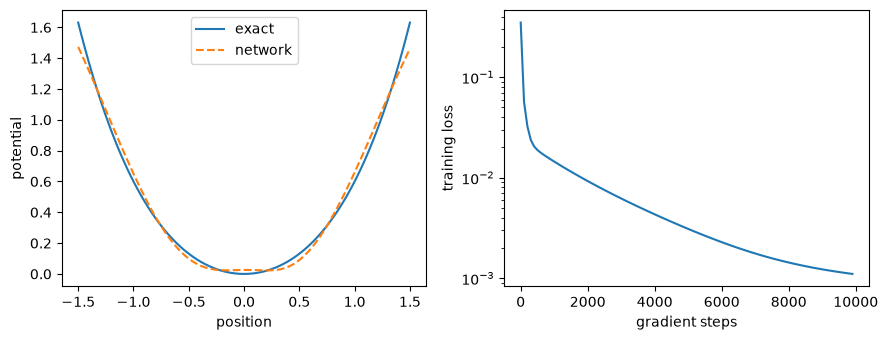

Training RMSE: 0.04672; directional gradient verified


In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(505)
x = np.linspace(-1.5, 1.5, 101)[:, None]
y = 0.5*x[:, 0]**2 + 0.1*x[:, 0]**4
w = rng.normal(size=24)
b = rng.normal(scale=.5, size=24)
v = rng.normal(scale=.15, size=24)
c = 0.0

def loss_and_grad(w, b, v, c):
    h = np.tanh(x*w[None, :] + b[None, :])
    residual = h @ v + c - y
    delta = residual[:, None]*v[None, :]*(1-h*h)/x.shape[0]
    return (np.mean(residual**2)/2,
            (np.sum(delta*x, axis=0), np.sum(delta, axis=0),
             h.T @ residual/x.shape[0], residual.mean()))

# A directional derivative catches mistakes across all parameter arrays.
direction = (rng.normal(size=24), rng.normal(size=24),
             rng.normal(size=24), float(rng.normal()))
loss, gradient = loss_and_grad(w, b, v, c)
epsilon = 1e-5
plus = loss_and_grad(w+epsilon*direction[0], b+epsilon*direction[1],
                     v+epsilon*direction[2], c+epsilon*direction[3])[0]
minus = loss_and_grad(w-epsilon*direction[0], b-epsilon*direction[1],
                      v-epsilon*direction[2], c-epsilon*direction[3])[0]
analytic = sum(np.sum(g*d) for g, d in zip(gradient, direction))
assert np.isclose((plus-minus)/(2*epsilon), analytic, rtol=1e-6, atol=1e-7)
history = []
for step in range(10000):
    loss, (gw, gb, gv, gc) = loss_and_grad(w, b, v, c)
    w -= .03*gw; b -= .03*gb; v -= .03*gv; c -= .03*gc
    if step % 100 == 0:
        history.append(loss)
prediction = np.tanh(x*w[None, :] + b[None, :]) @ v + c
rmse = np.sqrt(np.mean((prediction-y)**2))
assert rmse < .06
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].plot(x[:, 0], y, label='exact')
axes[0].plot(x[:, 0], prediction, '--', label='network')
axes[0].set(xlabel='position', ylabel='potential'); axes[0].legend()
axes[1].semilogy(np.arange(len(history))*100, history)
axes[1].set(xlabel='gradient steps', ylabel='training loss')
plt.tight_layout(); plt.show()
print(f'Training RMSE: {rmse:.5f}; directional gradient verified')

For honest prediction assessment, evaluate a denser independent grid and noisy independent measurements. For force assessment, differentiate the trained model and compare forces, not just energies. The code's assertion verifies a limited numerical target; it does not certify extrapolation or uncertainty.

## Gradient checks and scientific debugging

For a random direction $d$, compare $g^Td$ against $[L(\theta+hd)-L(\theta-hd)]/(2h)$ over several $h$. Agreement in a middle range, with deterioration for very large and very small $h$, is expected. A directional check is cheaper than checking every parameter and often detects transposes, missing averaging factors, or wrong signs. Repeat with several directions when debugging a complex model.

Use a fixed random sample when checking a deterministic derivative of a sampled loss; independent randomness in the two evaluations can overwhelm a finite difference. That procedure checks the derivative of the fixed-sample calculation. If samples are drawn from a parameter-dependent distribution, separately verify the statistical estimator for the full derivative.

AD differentiates control flow along the executed path. It does not make discontinuous decisions smooth, cure chaotic sensitivity, or validate a discretized differential equation. Complex-valued parameters require explicit conventions: the safest entry point is to treat real and imaginary parts as separate real parameters for a real loss. Chapter 9 carefully states its parameter convention before deriving complex wavefunction formulas.

## Exercises and worked solutions

1. Derive the allowed fixed learning rates for $L=(3\theta_1^2+7\theta_2^2)/2$.
2. For $L=(wx-y)^2/2$ derive the gradients with respect to $w$ and $x$, and explain why they answer different questions.
3. Why does reverse mode need to add adjoints at a branch rather than overwrite them?
4. A sampled objective depends on $\theta$ only through its probability density. What term remains in @eq-opt-score-gradient?

**Solutions.** (1) The Hessian eigenvalues are 3 and 7; require $0<\eta<2/7$. (2) $\partial_wL=(wx-y)x$ changes the model; $\partial_xL=(wx-y)w$ changes the input. The second can be used in inverse design but is not itself a parameter-training update. (3) For $L=a(v)+b(v)$, the derivative is the sum of both paths. Overwriting drops one contribution. (4) $\nabla L=\mathbb E[f\nabla\log p_\theta]$. Since $\mathbb E[\nabla\log p]=\nabla\int p=0$ under regularity, subtracting a constant baseline from $f$ leaves this expectation unchanged and can reduce variance.